# CCE3206 - Digital Signal Processing
## Practical 1: The sampling theorem

## Task 1

In [70]:
import numpy as np

# simulate for 0.1 s, with 1000 samples
duration = 0.1
N = 1000
# t is a list of 1000 time samples in [0, 0.1)
t = np.linspace(0, duration, N, endpoint=False)

# x is the signal x(t) = sin(2πFt)
x = np.sin(2 * np.pi * 100 * t)

# period of pulse train
train_period = 10
# width of single pulse
pulse_width = 1
# p is a periodic pulse train
p = np.arange(N) % train_period < pulse_width

# y is the sampled sinusoid
y = x * p

## Task 2

In [71]:
from scipy.fft import fft, fftfreq

# F is the list of frequencies for the DFT
F = fftfreq(N, duration / N)

# X(F) is the DFT of x(t)
X = fft(x) / N
# the power spectrum of X(F) is |X(F)|²
Xp = np.abs(X) ** 2

# Repeat for P(F) and Y(F):
P = fft(p) / N 
Pp = np.abs(P) ** 2 

Y = fft(y) / N
Yp = np.abs(Y) ** 2



## Task 3

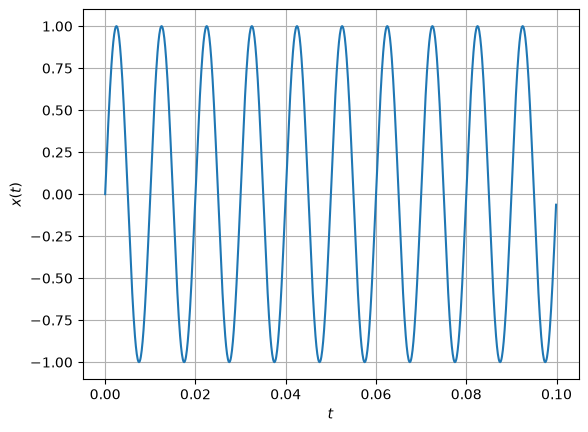

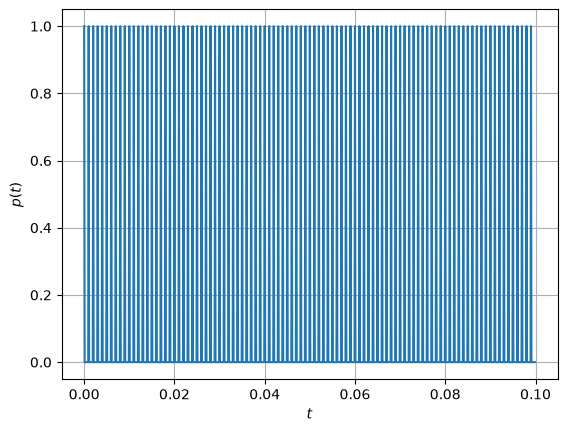

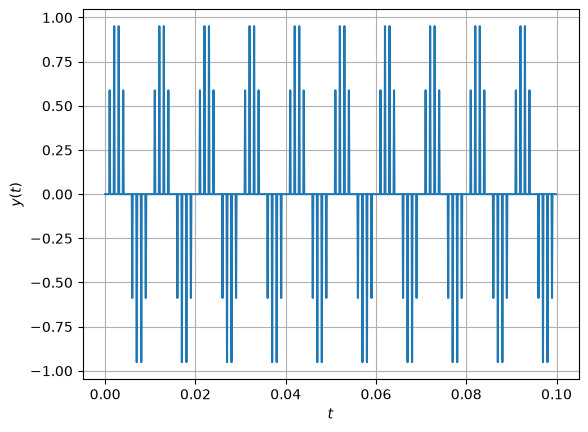

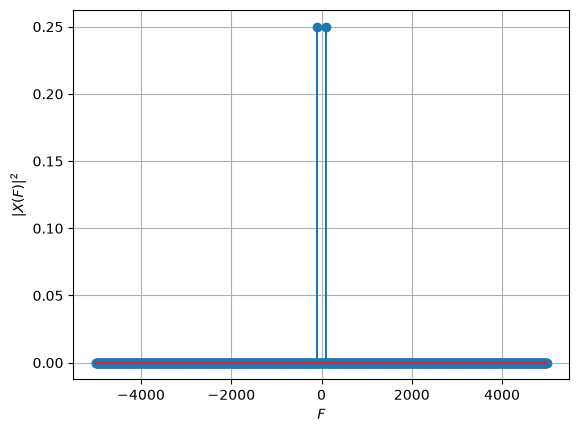

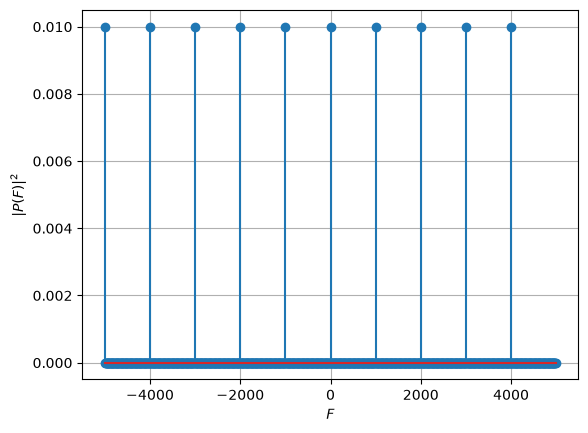

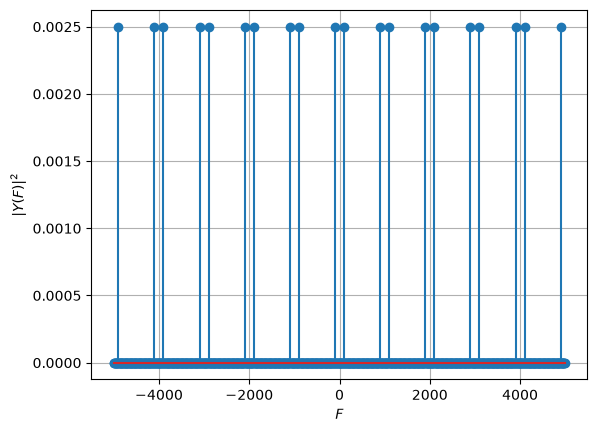

In [72]:
import matplotlib.pyplot as plt

# Plot x(t) against t
fig, ax = plt.subplots()
ax.plot(t, x)
ax.set_xlabel('$t$')
ax.set_ylabel('$x(t)$')
ax.grid(True)

# Repeat for p(t) and y(t)
fig, ax = plt.subplots()
ax.plot(t, p)
ax.set_xlabel('$t$')
ax.set_ylabel('$p(t)$')
ax.grid(True)

fig, ax = plt.subplots()
ax.plot(t, y)
ax.set_xlabel('$t$')
ax.set_ylabel('$y(t)$')
ax.grid(True)

# Plot |X(F)|^2 against F
fig, ax = plt.subplots()
ax.stem(F, Xp)
ax.set_xlabel('$F$')
ax.set_ylabel('$|X(F)|^2$')
ax.grid(True)

# Repeat for |P(F)|^2 and |Y(F)|^2
fig, ax = plt.subplots()
ax.stem(F, Pp)
ax.set_xlabel('$F$')
ax.set_ylabel('$|P(F)|^2$')
ax.grid(True)

fig, ax = plt.subplots()
ax.stem(F, Yp)
ax.set_xlabel('$F$')
ax.set_ylabel('$|Y(F)|^2$')
ax.grid(True)

plt.show()

## Task 4

From the values set for the pulse train: 
- The simulation sampling frequency is $F_{\text{sim}} = 1000/0.1 = 10{,}000$ Hz, (or 10kHz)

- The pulse train has a period of 10 simulation samples.

Therefore, the effective sampling frequency is:

$$
F_s = \frac{10000}{10} = 1000 \text{ Hz}
$$

This can be confirmed from the plot of $y(t)$ against $t$ by checking that consecutive sampling instants are present at a rate of 1000 Hz: 


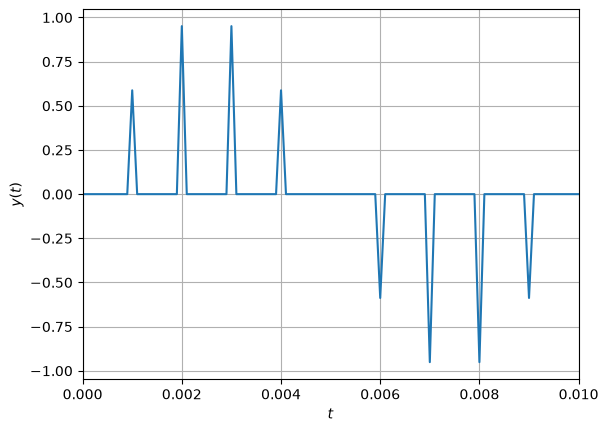

In [73]:
fig, ax = plt.subplots()
ax.plot(t, y)
ax.set_xlabel('$t$')
ax.set_ylabel('$y(t)$')
ax.grid(True)
ax.set_xlim([0, 0.01])
plt.show()

In the interval $0 \leq t < 0.01$ s, there are 10 sampling instants, spaced 0.001 s apart. Only eight spikes are visible because the samples at $t = 0$ s and $t = 0.005$ s have zero amplitude, where the sine wave crosses zero.

Since there are 10 samples in 0.01 seconds, the sampling frequency is $10 / 0.01 = 1000$ samples per second, confirming the calculated value of 1000 Hz.

## Task 5

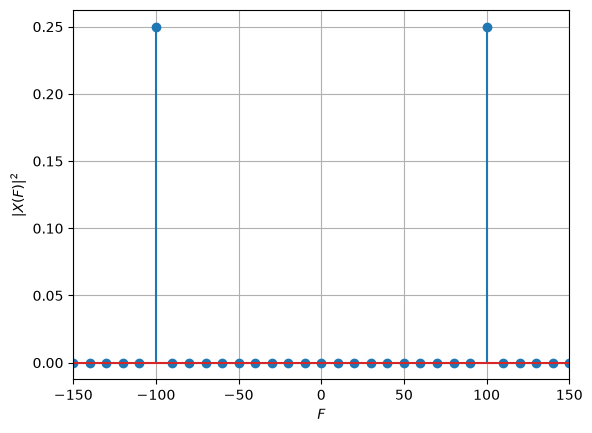

Frequency: 100.0 Hz
Power: 0.0025
Frequency: 900.0 Hz
Power: 0.0025
Frequency: 1100.0 Hz
Power: 0.0025
Frequency: 1900.0 Hz
Power: 0.0025
Frequency: 2100.0 Hz
Power: 0.0025
Frequency: 2900.0 Hz
Power: 0.0025
Frequency: 3100.0 Hz
Power: 0.0025
Frequency: 3900.0 Hz
Power: 0.0025
Frequency: 4100.0 Hz
Power: 0.0025
Frequency: 4900.0 Hz
Power: 0.0025
Frequency: -4900.0 Hz
Power: 0.0025
Frequency: -4100.0 Hz
Power: 0.0025
Frequency: -3900.0 Hz
Power: 0.0025
Frequency: -3100.0 Hz
Power: 0.0025
Frequency: -2900.0 Hz
Power: 0.0025
Frequency: -2100.0 Hz
Power: 0.0025
Frequency: -1900.0 Hz
Power: 0.0025
Frequency: -1100.0 Hz
Power: 0.0025
Frequency: -900.0 Hz
Power: 0.0025
Frequency: -100.0 Hz
Power: 0.0025


In [74]:

fig, ax = plt.subplots()
ax.stem(F, Xp)
ax.set_xlabel('$F$')
ax.set_ylabel('$|X(F)|^2$')
ax.set_xlim([-150, 150])
ax.grid(True)
plt.show()

for i in range(N):
    if Yp[i] > 0.0001:
        print("Frequency:", F[i], "Hz")
        print(f"Power: {Yp[i]:.4f}")

As shown in the graph above, the power spectrum of the unsampled sine wave $x(t)$ has frequency components at $-100$ Hz and $+100$ Hz, each with power 0.25.

Since the range was quite large for the power spectrum of the sampled sine wave $y(t)$, I coded a simple for loop to print out the frequency components. These are printed above, however for clarity's sake, I repeated them below. 

The sampled sine wave $y(t)$ has frequency components at:

$\pm100$, $\pm900$, $\pm1100$, $\pm1900$, $\pm2100$, $\pm2900$, $\pm3100$, $\pm3900$, $\pm4100$ and $\pm4900$ Hz.

Each component has a plotted power of approximately 0.0025. To obtain the corrected power, we multiply by:

$$
\left(\frac{F_{\text{sim}}}{F_s}\right)^2
= \left(\frac{10000}{1000}\right)^2 = 100
$$

Therefore, the corrected power of each component is:

$$
0.0025 \times 100 = 0.25
$$

## Task 6

#### Changing frequency and re-running simulation:

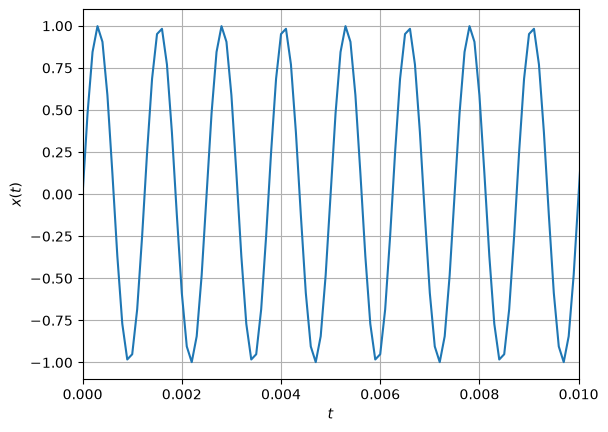

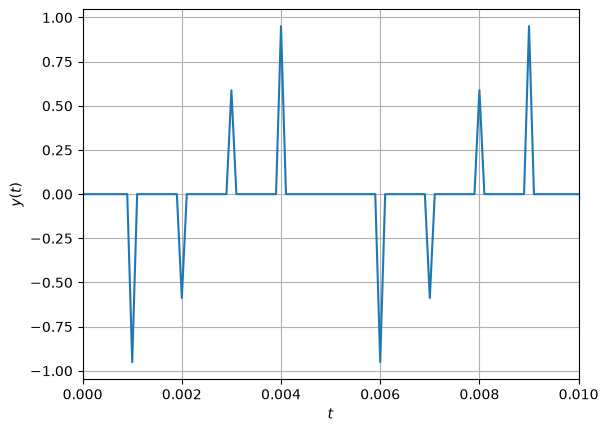

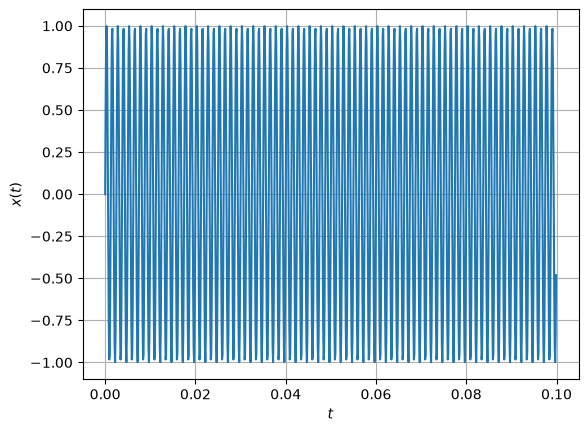

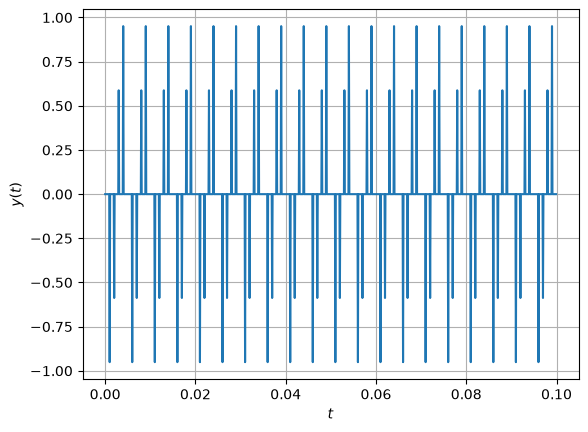

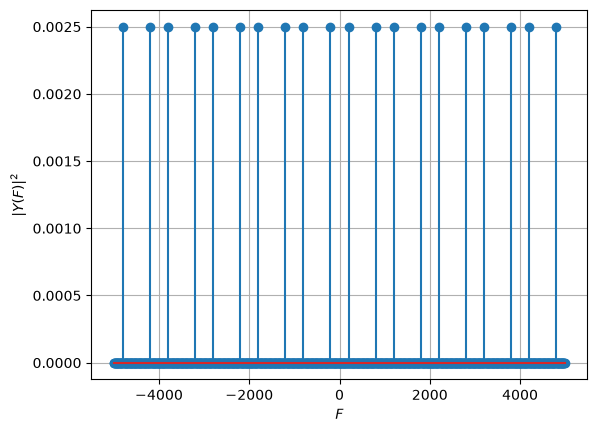

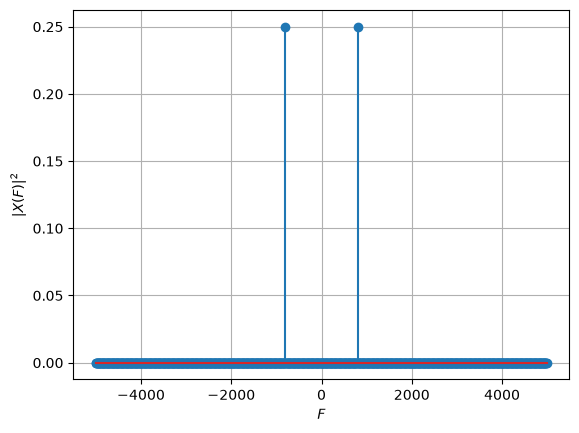

Frequency: 800.0 Hz
Power: 0.2500
Frequency: -800.0 Hz
Power: 0.2500
Frequency: 200.0 Hz
Power: 0.0025
Frequency: 800.0 Hz
Power: 0.0025
Frequency: 1200.0 Hz
Power: 0.0025
Frequency: 1800.0 Hz
Power: 0.0025
Frequency: 2200.0 Hz
Power: 0.0025
Frequency: 2800.0 Hz
Power: 0.0025
Frequency: 3200.0 Hz
Power: 0.0025
Frequency: 3800.0 Hz
Power: 0.0025
Frequency: 4200.0 Hz
Power: 0.0025
Frequency: 4800.0 Hz
Power: 0.0025
Frequency: -4800.0 Hz
Power: 0.0025
Frequency: -4200.0 Hz
Power: 0.0025
Frequency: -3800.0 Hz
Power: 0.0025
Frequency: -3200.0 Hz
Power: 0.0025
Frequency: -2800.0 Hz
Power: 0.0025
Frequency: -2200.0 Hz
Power: 0.0025
Frequency: -1800.0 Hz
Power: 0.0025
Frequency: -1200.0 Hz
Power: 0.0025
Frequency: -800.0 Hz
Power: 0.0025
Frequency: -200.0 Hz
Power: 0.0025


In [75]:
# Change the sine wave to 800 Hz
x = np.sin(2 * np.pi * 800 * t)

# Sample the new sine wave
y = x * p

# Recalculate the power spectra
X = fft(x) / N
Xp = np.abs(X) ** 2

Y = fft(y) / N
Yp = np.abs(Y) ** 2


# Repeat task 5 :

# Time domain plots: 
fig, ax = plt.subplots()
ax.plot(t, x)
ax.set_xlabel('$t$')
ax.set_ylabel('$x(t)$')
ax.grid(True)
ax.set_xlim([0, 0.01])
plt.show()

fig, ax = plt.subplots()
ax.plot(t, y)
ax.set_xlabel('$t$')
ax.set_ylabel('$y(t)$')
ax.set_xlim([0, 0.01])
ax.grid(True)
plt.show()

fig, ax = plt.subplots()
ax.plot(t, x)
ax.set_xlabel('$t$')
ax.set_ylabel('$x(t)$')
ax.grid(True)
plt.show()

fig, ax = plt.subplots()
ax.plot(t, y)
ax.set_xlabel('$t$')
ax.set_ylabel('$y(t)$')
ax.grid(True)
plt.show()
# Power spectrum plots: 
fig, ax = plt.subplots()
ax.stem(F, Yp)
ax.set_xlabel('$F$')
ax.set_ylabel('$|Y(F)|^2$')
ax.grid(True)
plt.show()

fig, ax = plt.subplots()
ax.stem(F, Xp)
ax.set_xlabel('$F$')
ax.set_ylabel('$|X(F)|^2$')
ax.grid(True)
plt.show()

for i in range(N):
    if Xp[i] > 0.0001:
        print("Frequency:", F[i], "Hz")
        print(f"Power: {Xp[i]:.4f}")

print("==============")

for i in range(N):
    if Yp[i] > 0.0001:
        print("Frequency:", F[i], "Hz")
        print(f"Power: {Yp[i]:.4f}")

#### Repeating of task 5: 
The unsampled sine wave $x(t)$ has frequency components at
$\pm800$ Hz, each with power 0.25

The sampled sine wave $y(t)$ has frequency components at:

$\pm200$, $\pm800$, $\pm1200$, $\pm1800$, $\pm2200$, $\pm2800$, $\pm3200$, $\pm3800$, $\pm4200$ and $\pm4800$ Hz.

Each component has a plotted power of approximately 0.0025. To obtain the corrected power, we multiply by:

$$
\left(\frac{F_{\text{sim}}}{F_s}\right)^2
= \left(\frac{10000}{1000}\right)^2 = 100
$$

Therefore, the corrected power of each component is:

$$
0.0025 \times 100 = 0.25
$$

#### Comments: 

What changed in this re-run simulation is the frequency of the sine wave from $100 Hz$ to $800Hz$; the sampling frequency remained the same ($1000 Hz$). 

The Nyquist frequency is half the sampling rate, therefore $500 Hz$; since the frequency of the sine wave is higher than the Nyquist frequency, **aliasing** occurs. This means that the from the samples, the original signal cannot be reconstructed. This is exemplified by the plots below this markdown cell. 

In comparison, the original 100 Hz sine wave was below the Nyquist frequency, so aliasing did not occur.


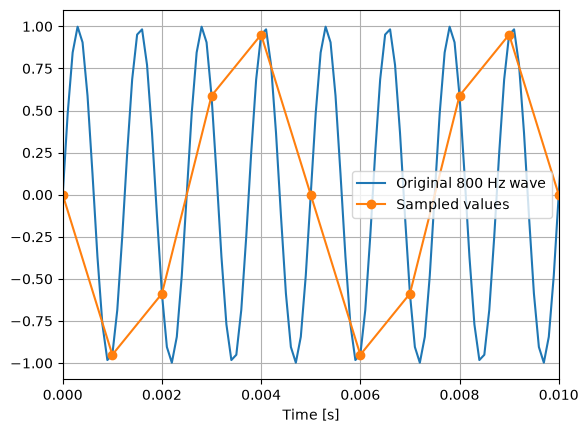

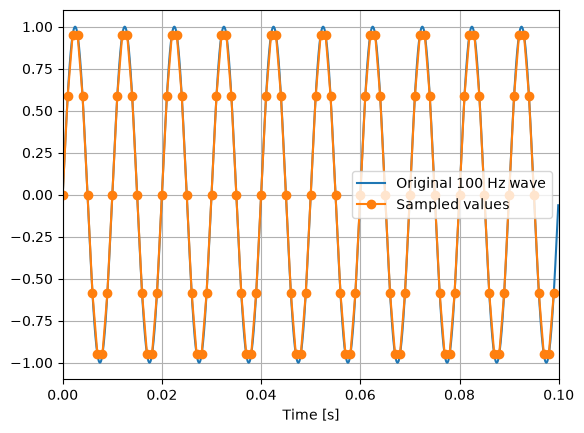

In [76]:
fig, ax = plt.subplots()

ax.plot(t, x, label='Original 800 Hz wave')
ax.plot(t[p], y[p], 'o-', label='Sampled values')

ax.set_xlim([0, 0.01])
ax.set_xlabel('Time [s]')
ax.legend()
ax.grid(True)
plt.show()

x = np.sin(2 * np.pi * 100 * t)
y = x * p

fig, ax = plt.subplots()
ax.plot(t, x, label='Original 100 Hz wave')
ax.plot(t[p], y[p], 'o-', label='Sampled values')

ax.set_xlim([0, 0.1])
ax.set_xlabel('Time [s]')
ax.legend()
ax.grid(True)
plt.show()

## Task 7

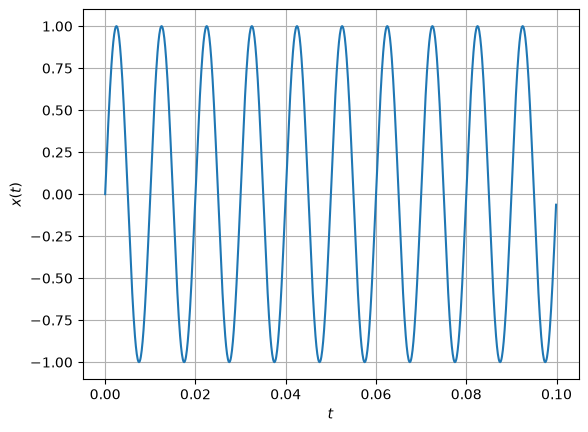

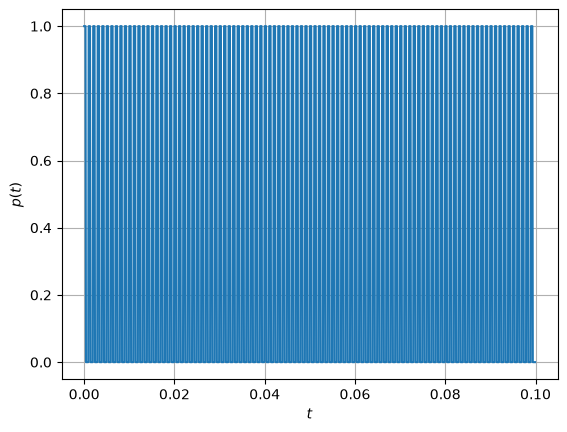

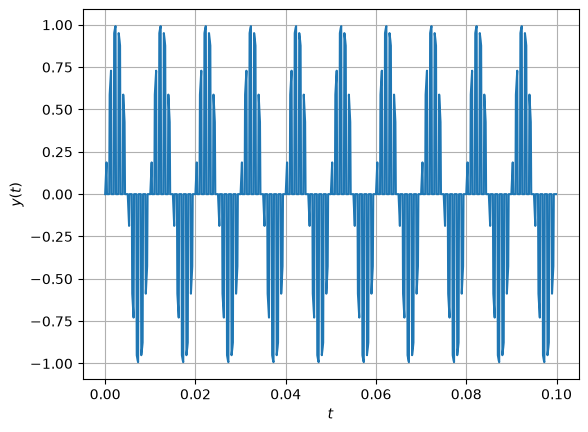

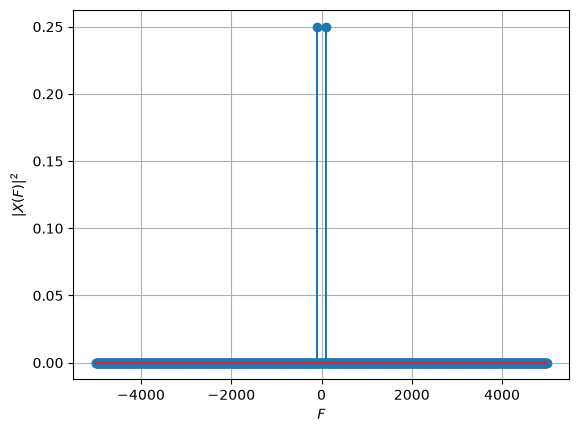

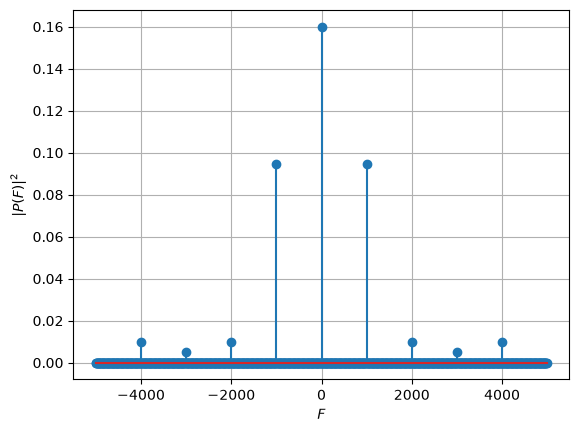

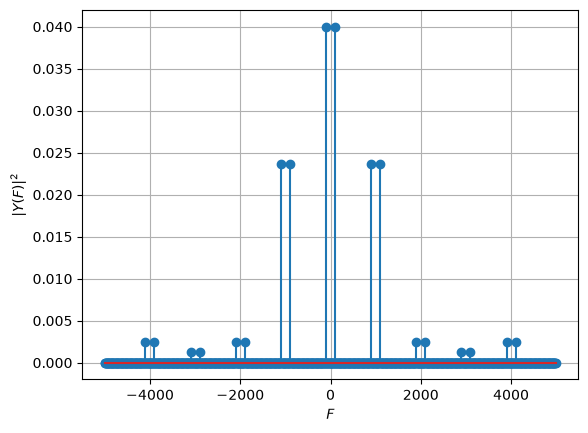

Frequency: 100.0 Hz
Power: 0.040000
Frequency: 900.0 Hz
Power: 0.023680
Frequency: 1100.0 Hz
Power: 0.023680
Frequency: 1900.0 Hz
Power: 0.002500
Frequency: 2100.0 Hz
Power: 0.002500
Frequency: 2900.0 Hz
Power: 0.001320
Frequency: 3100.0 Hz
Power: 0.001320
Frequency: 3900.0 Hz
Power: 0.002500
Frequency: 4100.0 Hz
Power: 0.002500
Frequency: -4100.0 Hz
Power: 0.002500
Frequency: -3900.0 Hz
Power: 0.002500
Frequency: -3100.0 Hz
Power: 0.001320
Frequency: -2900.0 Hz
Power: 0.001320
Frequency: -2100.0 Hz
Power: 0.002500
Frequency: -1900.0 Hz
Power: 0.002500
Frequency: -1100.0 Hz
Power: 0.023680
Frequency: -900.0 Hz
Power: 0.023680
Frequency: -100.0 Hz
Power: 0.040000


In [77]:
import matplotlib.pyplot as plt
# Return to a 100 Hz sine wave
x = np.sin(2 * np.pi * 100 * t)

# Increase the pulse width to 4 samples
pulse_width = 4
p = np.arange(N) % train_period < pulse_width

y = x * p

# Recalculate a power spectra
X = fft(x) / N
Xp = np.abs(X) ** 2

P = fft(p) / N
Pp = np.abs(P) ** 2

Y = fft(y) / N
Yp = np.abs(Y) ** 2


# Plot x(t) against t
fig, ax = plt.subplots()
ax.plot(t, x)
ax.set_xlabel('$t$')
ax.set_ylabel('$x(t)$')
ax.grid(True)

# Repeat for p(t) and y(t)
fig, ax = plt.subplots()
ax.plot(t, p)
ax.set_xlabel('$t$')
ax.set_ylabel('$p(t)$')
ax.grid(True)

fig, ax = plt.subplots()
ax.plot(t, y)
ax.set_xlabel('$t$')
ax.set_ylabel('$y(t)$')
ax.grid(True)

# Plot |X(F)|^2 against F
fig, ax = plt.subplots()
ax.stem(F, Xp)
ax.set_xlabel('$F$')
ax.set_ylabel('$|X(F)|^2$')
ax.grid(True)

# Repeat for |P(F)|^2 and |Y(F)|^2
fig, ax = plt.subplots()
ax.stem(F, Pp)
ax.set_xlabel('$F$')
ax.set_ylabel('$|P(F)|^2$')
ax.grid(True)

fig, ax = plt.subplots()
ax.stem(F, Yp)
ax.set_xlabel('$F$')
ax.set_ylabel('$|Y(F)|^2$')
ax.grid(True)

plt.show()

for i in range(N):
    if Yp[i] > 0.000001:
        print("Frequency:", F[i], "Hz")
        print(f"Power: {Yp[i]:.6f}")

#### Repeating of task 5:

The unsampled sine wave $x(t)$ has frequency components at
$\pm100$ Hz, each with power 0.25.

The sampled sine wave $y(t)$ has frequency components at:

$\pm100$, $\pm900$, $\pm1100$, $\pm1900$, $\pm2100$, $\pm2900$, $\pm3100$, $\pm3900$ and $\pm4100$ Hz.

The components have different plotted powers. To obtain the corrected powers, we multiply by:

$$
\left(\frac{F_{\text{sim}}}{F_s}\right)^2
= \left(\frac{10000}{1000}\right)^2 = 100
$$

Therefore, the measured and corrected powers are:

| Frequency components (Hz) | Measured power per component | Corrected power per component |
|---|---:|---:|
| $\pm100$ | 0.040000 | 4.000000 |
| $\pm900$, $\pm1100$ | 0.023680 | 2.368034 |
| $\pm1900$, $\pm2100$ | 0.002500 | 0.250000 |
| $\pm2900$, $\pm3100$ | 0.001320 | 0.131966 |
| $\pm3900$, $\pm4100$ | 0.002500 | 0.250000 |

#### Comments:

Increasing the pulse width from 1 to 4 samples keeps each pulse on for four times longer. Therefore, $y(t)$ contains wider sections of the original sine wave.

The highest measured power of $y(t)$ increased from 0.0025 to 0.04, at $\pm100 Hz$. The frequency components now have different powers, unlike the one sample pulse case where they all had power 0.0025. The peaks at $\pm4900$ Hz also practically disappear.

## Task 8

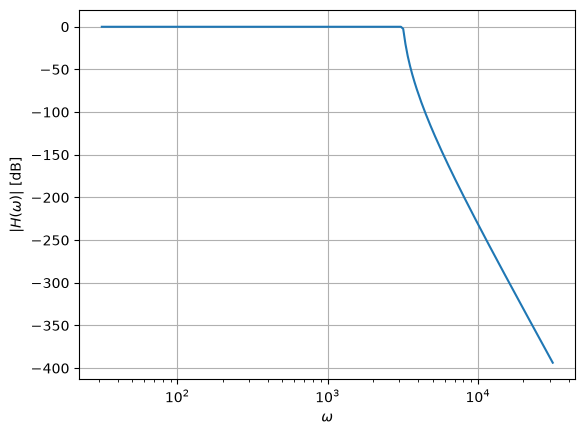

In [78]:
from scipy import signal 

# passband cut-off frequency
wp = 2 * np.pi * 500
# stopband edge frequency
ws = 2 * np.pi * 600
# maximum loss in passband (dB)
rp = 0.1
# minimum attenuation in stopband (dB)
rs = 60

# determine the order of the Chebyshev filter
[n, wn] = signal.cheb1ord(
    wp, ws, rp, rs, analog=True
)
# determine the transfer function
[bnorm, anorm] = signal.cheby1(n, rp, 1, analog=True)
# determine the response of the filter
[w, h] = signal.freqs(bnorm, anorm)

# plot the response
fig, ax = plt.subplots()
ax.semilogx(wn * w, 20 * np.log10(abs(h )))
ax.set_xlabel('$\\omega$')
ax.set_ylabel('$|H(\\omega)|$ [dB]')
ax.grid(True)
plt.show()

## Task 9

In [79]:
# Change the sine wave to 400 Hz
x = np.sin(2 * np.pi * 400 * t)

# Reset the pulse width to 1 sample
pulse_width = 1
p = np.arange(N) % train_period < pulse_width

# Recalculate the sampled signal
y = x * p

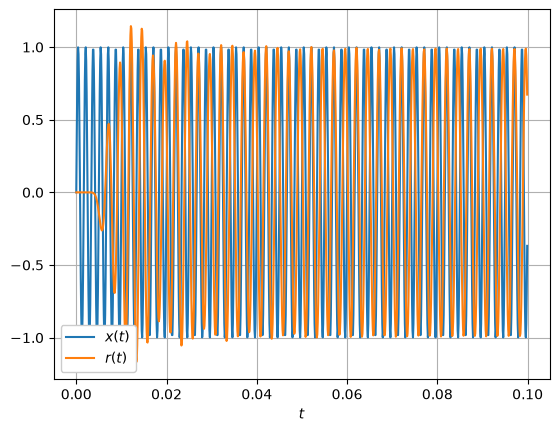

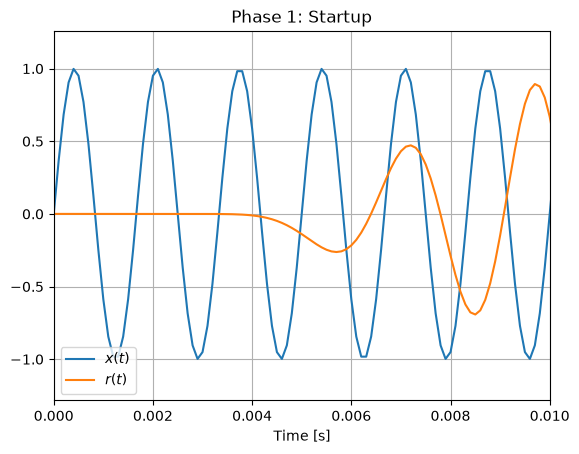

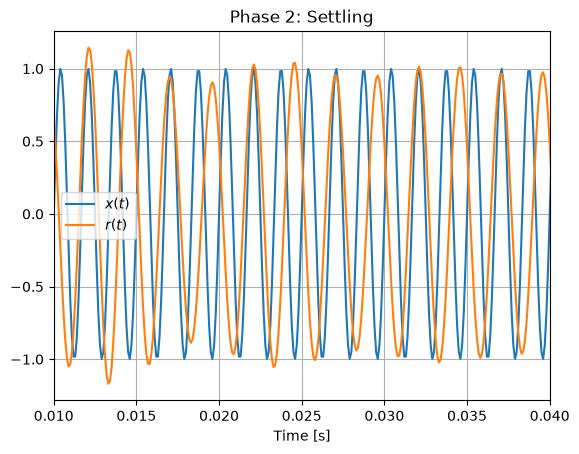

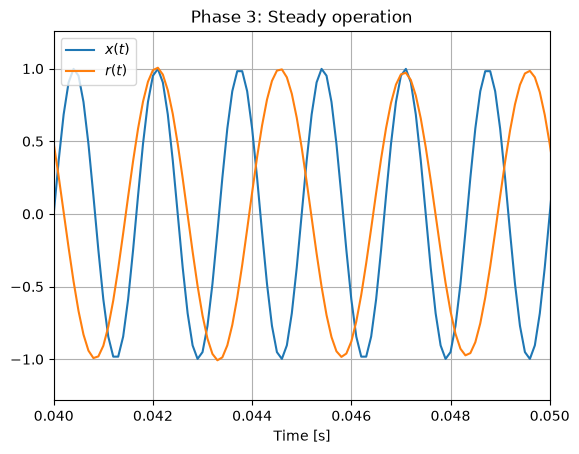

In [83]:
# simulate the filter operation
tr, r, state = signal.lsim((bnorm, anorm), U=y, T=wn * t)

# plot x(t) and r(t)
fig, ax = plt.subplots()
ax.plot(t, x, label='$x(t)$')
ax.plot(t, train_period * r, label='$r(t)$')
ax.set_xlabel('$t$')
ax.legend(loc='best', framealpha=1)
ax.grid(True)
plt.show()

# Phase 1: startup
fig, ax = plt.subplots()
ax.plot(t, x, label='$x(t)$')
ax.plot(t, train_period * r, label='$r(t)$')
ax.set_xlim([0, 0.01])
ax.set_title('Phase 1: Startup')
ax.set_xlabel('Time [s]')
ax.legend()
ax.grid(True)
plt.show()

# Phase 2: settling
fig, ax = plt.subplots()
ax.plot(t, x, label='$x(t)$')
ax.plot(t, train_period * r, label='$r(t)$')
ax.set_xlim([0.01, 0.04])
ax.set_title('Phase 2: Settling')
ax.set_xlabel('Time [s]')
ax.legend()
ax.grid(True)
plt.show()

# Phase 3: steady operation
fig, ax = plt.subplots()
ax.plot(t, x, label='$x(t)$')
ax.plot(t, train_period * r, label='$r(t)$')
ax.set_xlim([0.04, 0.05])
ax.set_title('Phase 3: Steady operation')
ax.set_xlabel('Time [s]')
ax.legend()
ax.grid(True)
plt.show()

#### Comments:

During startup, the reconstructed signal $r(t)$ is initially close to zero before its amplitude begins to increase.

During settling, its amplitude briefly exceeds that of the original signal, then gradually settles to approximately the same amplitude. It's amplitude also sometimes dips below that of the original signal at times.

During steady operation, $r(t)$ has approximately the same amplitude and frequency as the original 400 Hz sine wave. However, the peaks do not line up exactly, showing that the filter introduces a phase shift.

Since 400 Hz is within the filter's passband of 500 Hz, the original sine wave is able to be recovered. 

## Task 10

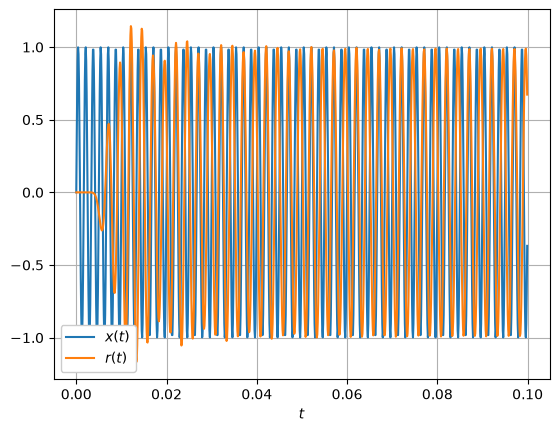

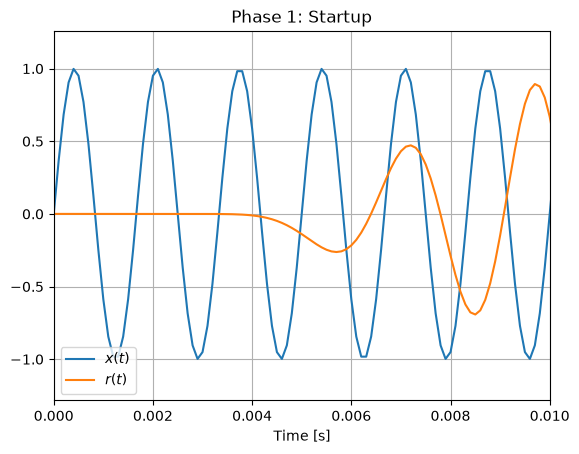

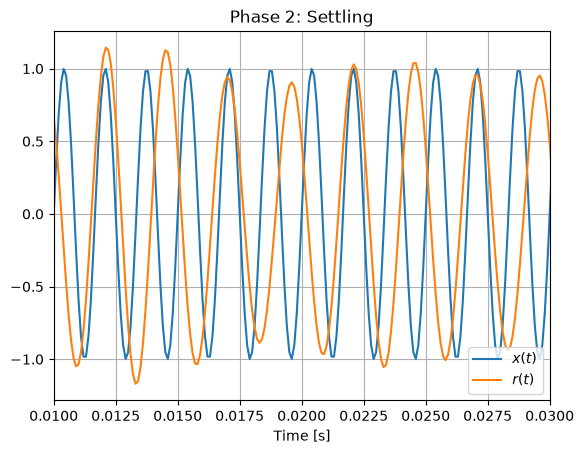

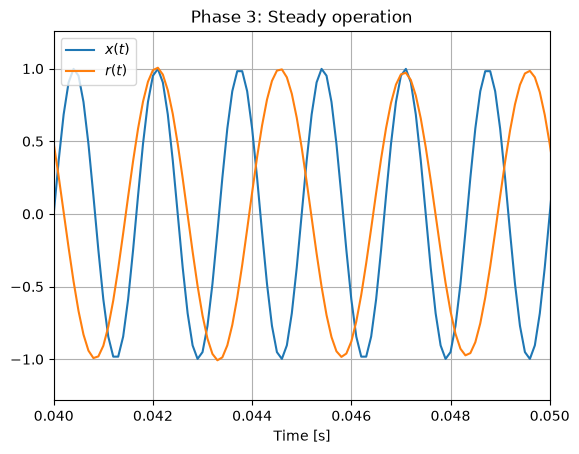

In [ ]:
# Change the sine wave to 600 Hz
x = np.sin(2 * np.pi * 600 * t)

# Reset the pulse width to 1 sample
pulse_width = 1
p = np.arange(N) % train_period < pulse_width

# Recalculate the sampled signal
y = x * p

# Simulate the filter operation
tr, r, state = signal.lsim((bnorm, anorm), U=y, T=wn * t)

# Plot x(t) and r(t)
fig, ax = plt.subplots()
ax.plot(t, x, label='$x(t)$')
ax.plot(t, train_period * r, label='$r(t)$')
ax.set_xlabel('$t$')
ax.legend(loc='best', framealpha=1)
ax.grid(True)
plt.show()

# Phase 1: startup
fig, ax = plt.subplots()
ax.plot(t, x, label='$x(t)$')
ax.plot(t, train_period * r, label='$r(t)$')
ax.set_xlim([0, 0.01])
ax.set_title('Phase 1: Startup')
ax.set_xlabel('Time [s]')
ax.legend()
ax.grid(True)
plt.show()

# Phase 2: settling
fig, ax = plt.subplots()
ax.plot(t, x, label='$x(t)$')
ax.plot(t, train_period * r, label='$r(t)$')
ax.set_xlim([0.01, 0.04])
ax.set_title('Phase 2: Settling')
ax.set_xlabel('Time [s]')
ax.legend()
ax.grid(True)
plt.show()

# Phase 3: steady operation
fig, ax = plt.subplots()
ax.plot(t, x, label='$x(t)$')
ax.plot(t, train_period * r, label='$r(t)$')
ax.set_xlim([0.04, 0.05])
ax.set_title('Phase 3: Steady operation')
ax.set_xlabel('Time [s]')
ax.legend()
ax.grid(True)
plt.show()

#### Comments:

The startup and settling phases are very similar to those of task 9, with initial amplitude of the reconstructed signal close to 0 during startup, and the settling phase having some larger or smaller peaks in amplitude compared to the original signal. 

Although the filter in task 9 introduced a phase shift, the original and reconstructed signals oscillated at the same speed; this is not the case for task 10. The output oscillates more slowly than the original 600 Hz sine wave. Sampling at 1000 Hz introduces an aliased component at $1000 - 600 = 400$ Hz.

The filter passes this 400 Hz component while strongly reducing the original 600 Hz component. Therefore, a similar output amplitude does not mean the original signal has been recovered.

In Task 9, the filter approximately recovered the original 400 Hz signal. In Task 10, the output is approximately 400 Hz even though the original signal is 600 Hz, so reconstruction is unsuccessful.